In [4]:
import xarray as xr
import numpy as np
import cftime
import xesmf as xe
import TCs
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy import stats
import pandas as pd
from scipy.ndimage import gaussian_filter

import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature
from cartopy.crs import PlateCarree, Robinson
import matplotlib.colors as mcolors
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
import matplotlib as mpl
import Plot

In [2]:
import matplotlib.transforms as mtransforms

def add_lat_labels(ax, lats=(-60, -30, 0, 30, 60), pad=3, fontsize=8):
    lon_0 = ax.projection.proj4_params.get('lon_0', 0.0)
    trans = mtransforms.offset_copy(ax.transData, fig=ax.figure,
                                    x=-pad, y=0, units='points')
    for lat in lats:
        x, y = ax.projection.transform_point(lon_0 - 179.99, lat, ccrs.PlateCarree())
        suffix = 'N' if lat > 0 else 'S' if lat < 0 else ''
        ax.text(x, y, f'{abs(lat)}°{suffix}', transform=trans,
                ha='right', va='center', fontsize=fontsize, clip_on=False)

def add_graticule(ax, lat_labels=False):
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(), draw_labels=False,
        linewidth=0.6, color='gray', alpha=0.8, linestyle=':', zorder=20
    )
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
    gl.top_labels = gl.right_labels= gl.left_labels = False
    gl.bottom_labels = lat_labels
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}
    gl.xpadding = 1.5 
    return gl

In [21]:
# dataset for T2M&SST annual climatology
ds = xr.open_dataset('Figure4.nc')

cmap2, levels2, norm2  = Plot.def_colormap(max=8, white=0.5, interval=1, cmap='RdBu_r')
var1 = 'TREFHT'; var2='TS'
datasets = [
    (ds['clim_sdcam_t2m'], ds['clim_sdcam_sst'], ds['icemask_sdcam'], "CAM-LR", 'a'), 
    (ds['clim_hicam_t2m'], ds['clim_hicam_sst'], ds['icemask_hicam'], "CAM-HR", 'b'), 
    (ds['clim_era5_t2m'], ds['clim_era5_sst'], ds['icemask_era5'], "ERA5", 'c'),
]

diff_ds = [
    (ds['diff1_t2m'], 0.99, ds['diff1_sst'], 1.00, ds['icemask_sdcam'], "CAM-LR \N{MINUS SIGN} ERA5", 'd'),
    (ds['diff2_t2m'], 1.00, ds['diff2_sst'], 1.00, ds['icemask_sdcam'], "CAM-HR \N{MINUS SIGN} ERA5", 'e'),
    (ds['diff3_t2m'], 1.00, ds['diff3_sst'], 1.00, ds['icemask_sdcam'], "CAM-HR \N{MINUS SIGN} CAM-LR", 'f'),
]

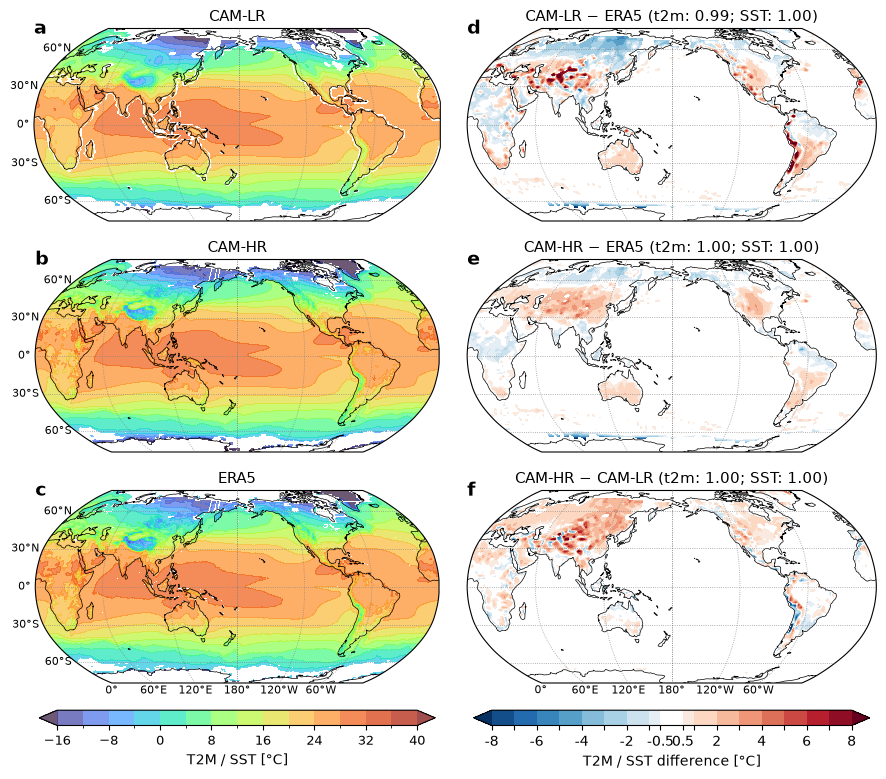

In [22]:
fig, axs = plt.subplots(ncols=2, nrows=3, figsize=(11,8.5),
                        subplot_kw={"projection": ccrs.Robinson(central_longitude=180)})
plt.subplots_adjust(wspace=0.04)

for ax, (t2m, sst, icemask_now, title, label) in zip(axs[:,0], datasets):

    cf = t2m.where(icemask_now==0).plot.contourf(
        ax=ax, transform=ccrs.PlateCarree(), levels=np.arange(-16, 40+4, 4), cmap='turbo',alpha=0.7, 
        extend="both", add_colorbar=False
    )
    sst.where(icemask_now==0).plot.contourf(
        ax=ax, transform=ccrs.PlateCarree(), levels=np.arange(-16, 40+4, 4), cmap='turbo',alpha=0.7, 
        extend="both", add_colorbar=False
    )
    ax.coastlines(linewidth=0.5)
    ax.set_title(None, fontsize=11)
    ax.text(0.5, 1.02, title, transform=ax.transAxes, fontsize=11, ha='center', va='bottom')
    ax.annotate(label, xy=(0, 1.05), xycoords='axes fraction', fontsize=14, fontweight='bold', ha='left', va='top')
    add_graticule(ax, lat_labels=(label=='c'))
    add_lat_labels(ax)
    
for ax, (t2m, corr, sst, corr2, icemask_now, title, label) in zip(axs[:,1], diff_ds):
    icemask_now = icemask_now.rename({'lat_sdcam':"lat", 'lon_sdcam':'lon'})
    cf2 = t2m.where(icemask_now==0).plot.contourf(
        ax=ax, transform=ccrs.PlateCarree(), 
        levels=levels2, cmap=cmap2, norm=norm2,
        extend="both", add_colorbar=False
    )
    sst.where(icemask_now==0).plot.contourf(
        ax=ax, transform=ccrs.PlateCarree(), 
        levels=levels2, cmap=cmap2, norm=norm2,
        extend="both", add_colorbar=False
    )
    ax.coastlines(linewidth=0.5)
    ax.set_title(None, fontsize=11)
    ax.text(0.5, 1.02, f'{title} (t2m: {corr:.2f}; SST: {corr2:.2f})', transform=ax.transAxes, fontsize=11, ha='center', va='bottom')
    ax.annotate(label, xy=(0, 1.05), xycoords='axes fraction', fontsize=14, fontweight='bold', ha='left', va='top')
    add_graticule(ax, lat_labels=(label=='f'))
    
cax = fig.add_axes([0.135, 0.06, 0.36, 0.018])   # [left, bottom, width, height] in figure coords
cbar = fig.colorbar(cf, cax=cax, orientation='horizontal', spacing='uniform', extend='both')
cbar.set_label(r'T2M / SST [°C]')
cbar.ax.tick_params(labelsize=9)
cax = fig.add_axes([0.53, 0.06, 0.36, 0.018])  # [left, bottom, width, height] in figure coords
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap2, norm=norm2),
                    cax=cax, orientation='horizontal', ticks=levels2[levels2 != 0], 
                    extend='both', spacing='proportional')
major_ticks = [-8, -6, -4, -2, -0.5, 0.5, 2, 4, 6, 8]
major_labels = [ '' if t not in major_ticks else f'{t:g}' for t in levels2[levels2 != 0]]
cbar.minorticks_off()
cbar.ax.set_xticklabels(major_labels, minor=False)
cbar.set_label(r'T2M / SST difference [°C]')

# plt.savefig(f'Figure4.png', bbox_inches='tight', dpi=300)

In [8]:
# dataset for PRECT(absolute diff)&PS annual climatology
ds = xr.open_dataset('Figure5.nc')

levels = np.linspace(0, 12, 13)
var1 = 'PRECT'; var2 = 'PS'
datasets = [
    (ds['clim_sdcam_prect'], ds['clim_sdcam_ps'], "CAM-LR", 'a'), 
    (ds['clim_hicam_prect'], ds['clim_hicam_ps'], "CAM-HR", 'b'), 
    (ds['clim_era5_prect'], ds['clim_era5_ps'], "ERA5", 'c'),
]
cmap2, levels2, norm2 = Plot.def_colormap(max=5, white=0.2, interval=0.5, cmap='BrBG')

diff_ds = [
    (ds['diff1_prect'], 0.92, ds['diff1_ps'], 0.94, "CAM-LR \N{MINUS SIGN} ERA5", 'd'),
    (ds['diff2_prect'], 0.93, ds['diff2_ps'], 0.99, "CAM-HR \N{MINUS SIGN} ERA5", 'e'),
    (ds['diff3_prect'], 0.92, ds['diff3_ps'], 0.94, "CAM-HR \N{MINUS SIGN} CAM-LR", 'f'),
]

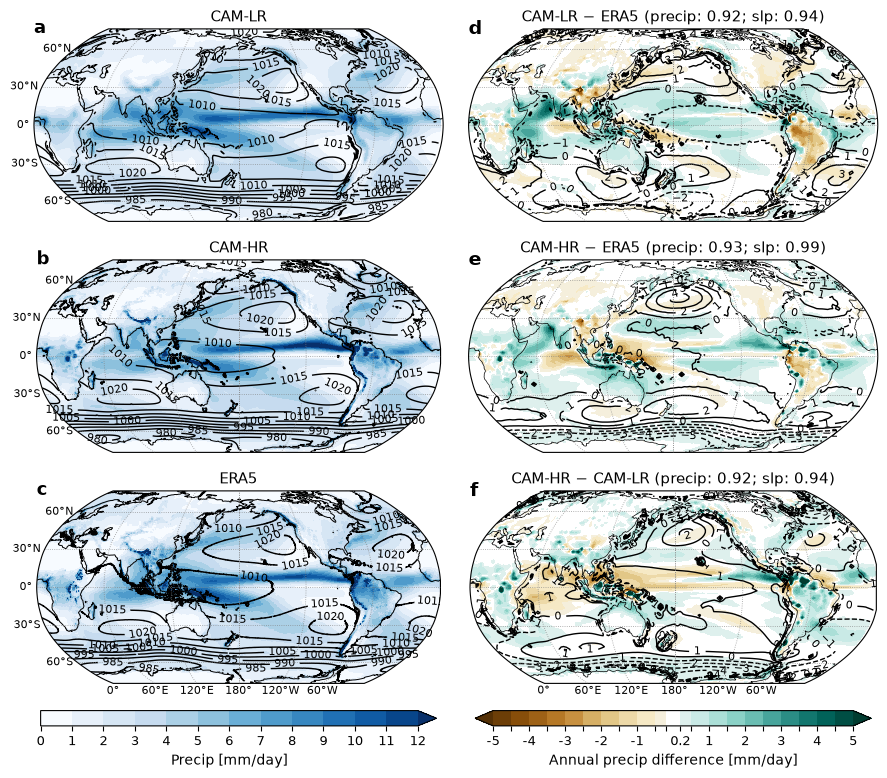

In [10]:
fig, axs = plt.subplots(ncols=2, nrows=3, figsize=(11,8.5),
                        subplot_kw={"projection": ccrs.Robinson(central_longitude=180)})
plt.subplots_adjust(wspace=0.04)

for ax, (precip, ps, title, label) in zip(axs[:,0], datasets):
    cf = precip.plot.contourf(
        ax=ax, transform=ccrs.PlateCarree(), levels=levels, cmap="Blues", 
        extend="max", add_colorbar=False
    )
    cs = (ps/100).plot.contour(
        ax=ax, transform=ccrs.PlateCarree(), 
        colors='black', levels=np.arange(980, 1031, 5), add_colorbar=False, 
        linewidths=1.0, zorder=10
    )
    cs.clabel(fontsize=8)
    ax.coastlines(linewidth=0.7)
    ax.set_title(None, fontsize=11)
    ax.text(0.5, 1.02, title, transform=ax.transAxes, fontsize=11, ha='center', va='bottom')
    ax.annotate(label, xy=(0, 1.05), xycoords='axes fraction', fontsize=13, fontweight='bold', ha='left', va='top')
    add_graticule(ax, lat_labels=(label=='c'))
    add_lat_labels(ax)

for ax, (precip, precip_corr, ps, ps_corr, title, label) in zip(axs[:,1], diff_ds):
    cf2 = precip.plot.contourf(
        ax=ax, transform=ccrs.PlateCarree(), 
        levels=levels2, cmap=cmap2, norm=norm2, 
        extend="both", add_colorbar=False
    )
    cs = (ps/100).plot.contour(
        ax=ax, transform=ccrs.PlateCarree(), 
        colors='black', levels=np.arange(-5, 5.1, 1), add_colorbar=False, 
        linewidths=1.0, zorder=10
    )
    cs.clabel(fontsize=8)
    ax.coastlines(linewidth=0.5)
    ax.set_title(None, fontsize=11)
    ax.text(0.5, 1.02, f'{title} (precip: {precip_corr:.2f}; slp: {ps_corr:.2f})', transform=ax.transAxes, fontsize=11, ha='center', va='bottom')
    ax.annotate(label, xy=(0, 1.05), xycoords='axes fraction', fontsize=14, fontweight='bold', ha='left', va='top')
    add_graticule(ax, lat_labels=(label=='f'))

cax = fig.add_axes([0.135, 0.06, 0.36, 0.018])  # [left, bottom, width, height] in figure coords

cbar = fig.colorbar(cf, cax=cax, orientation='horizontal', spacing='uniform', extend='both',
                    ticks=levels)
cbar.set_label(r'Precip [mm/day]')
cbar.ax.tick_params(labelsize=9)
cax = fig.add_axes([0.53, 0.06, 0.36, 0.018])  # [left, bottom, width, height] in figure coords

cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap2, norm=norm2),
                    cax=cax, orientation='horizontal', ticks=levels2[levels2 != 0], 
                    extend='both', spacing='proportional')
major_ticks = [-5, -4, -3, -2, -1, 0.2, 1, 2, 3, 4, 5, ]
major_labels = [ '' if t not in major_ticks else f'{t:g}' for t in levels2[levels2 != 0]]
cbar.minorticks_off()
cbar.ax.set_xticklabels(major_labels, minor=False)
cbar.set_label(r'Annual precip difference [mm/day]')
cbar.ax.tick_params(labelsize=9)

# plt.savefig(f'Figure5.png', bbox_inches='tight', dpi=300)